<a href="https://colab.research.google.com/github/tanvirrahman0070-dev/House-Price-Prediction-Group-1/blob/main/Group1_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction Using Linear Regression (Group 1)

## Abstract
This study predicts median owner-occupied home values (`MEDV`) using **Simple Linear Regression** (based on average room count, `RM`) and **Multiple Linear Regression** (using all 13 housing predictors) on the Boston Housing dataset. After preprocessing and removing target outliers via the Interquartile Range (IQR) method, **Multiple Linear Regression achieved the strongest performance with an $R^2$ of 0.7525 and an RMSE of 3.1511 (1,000s USD)**, substantially outperforming Simple Linear Regression ($R^2 = 0.1610$, $\text{RMSE} = 5.8016$).

## Dataset Source & Citation
* **Source Link:** [Boston Housing Dataset on OpenML (Data ID: 531)](https://openml.org) | [GitHub Repository CSV](https://githubusercontent.com)
* **Citation:** The dataset originates from the seminal hedonic housing price study by Harrison and Rubinfeld (1978), comprising 506 census tracts in the Boston metropolitan area across 14 variables.

## Preprocessing & Reproducibility
To ensure full reproducibility, a fixed random seed (`RANDOM_STATE = 42`) is applied across all operations:
1. **Data Cleaning:** Checked for duplicate entries (0 found) and missing values (0 found, with median imputation configured as a safeguard).
2. **Outlier Removal:** Applied the $1.5 \times \text{IQR}$ rule to `MEDV`, removing 40 extreme upper-end outliers and retaining **466 clean records** (see **Table 1** and **Table 2** below for initial data structure and descriptive statistics).
3. **Splitting & Scaling:** Partitioned the cleaned data into an **80% training set (372 rows)** and **20% test set (94 rows)** before applying `StandardScaler` inside `scikit-learn` pipelines (Pedregosa et al., 2011) to prevent data leakage.


Dataset shape (rows, columns): (506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    float64
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB

--- Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
crim,506.0,3.61,8.60,0.01,0.08,0.26,3.68,88.98
zn,506.0,11.36,23.32,0.00,0.00,0.00,12.50,100.00
indus,506.0,11.14,6.86,0.46,5.19,9.69,18.10,27.74
chas,506.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
nox,506.0,0.55,0.12,0.38,0.45,0.54,0.62,0.87
rm,506.0,6.28,0.70,3.56,5.89,6.21,6.62,8.78
age,506.0,68.57,28.15,2.90,45.02,77.50,94.07,100.00
dis,506.0,3.80,2.11,1.13,2.10,3.21,5.19,12.13
rad,506.0,9.55,8.71,1.00,4.00,5.00,24.00,24.00
tax,506.0,408.24,168.54,187.00,279.00,330.00,666.00,711.00


Missing values: 0
Duplicate rows: 0
Rows before outlier removal: 506 | After outlier removal: 466


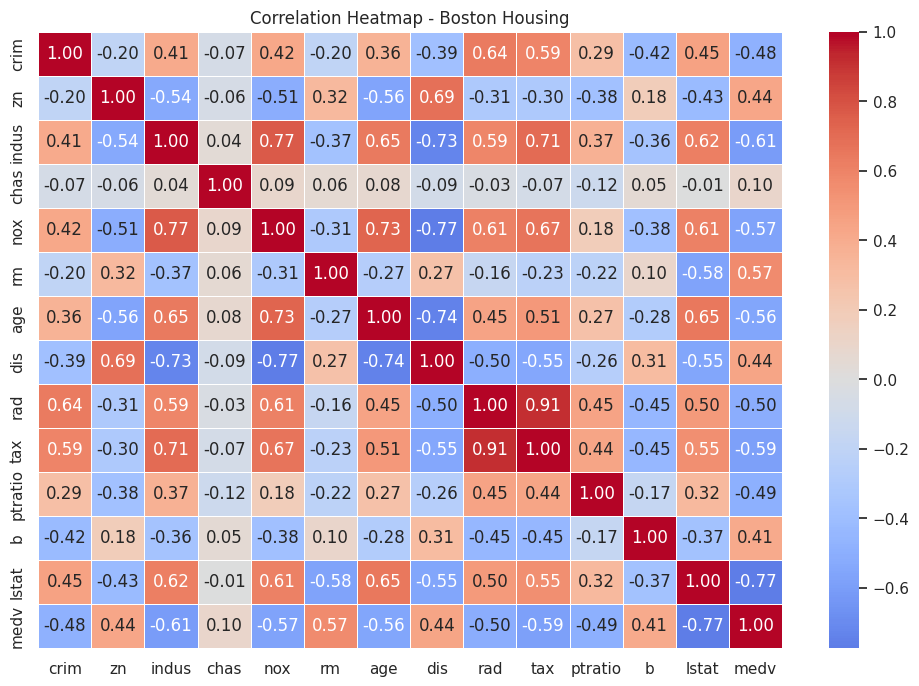

Train shape: (372, 13) | Test shape: (94, 13)


,MAE,MSE,RMSE,R2
Model,,,,
Simple Linear Regression (RM only),3.9584,33.6589,5.8016,0.1610
Multiple Linear Regression (All Features),2.2310,9.9293,3.1511,0.7525


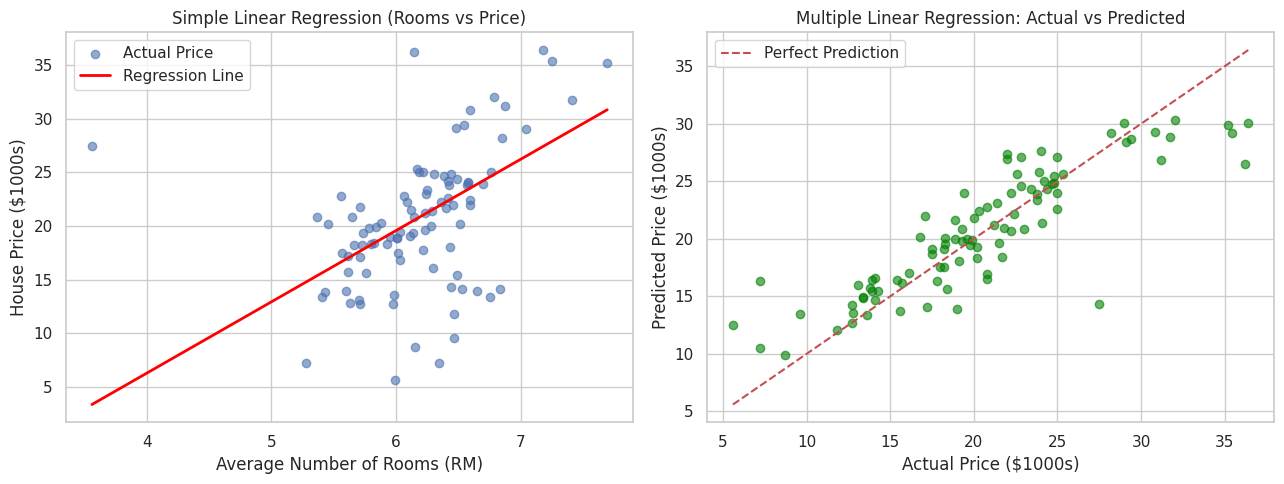


### Conclusion & Limitations
* **Best Model:** **Multiple Linear Regression (All Features)** outperformed Simple Linear Regression with **$R^2 = 0.7525$** and **$RMSE = 3.1511$** ($1000s).
* **Limitations:** The Boston Housing dataset contains 506 rows (466 after IQR outlier removal), so scores can vary slightly across train/test splits.
* **Next Steps:** Try cross-validation, polynomial features, or tree-based models (like Random Forest or Gradient Boosting) to capture non-linear relationships.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")

try:
    boston = fetch_openml(data_id=531, as_frame=True, parser="auto")
    df = boston.frame.copy()
    df.columns = [col.lower() for col in df.columns]
    for col in df.columns:
        df[col] = pd.to_numeric(df[col])
except Exception:
    import statsmodels.api as sm
    df = sm.datasets.get_rdataset("Boston", "MASS").data.copy()
    df.columns = [col.lower() for col in df.columns]

print("Dataset shape (rows, columns):", df.shape)
display(df.head())


print("\n--- Dataset Info ---")
df.info()
print("\n--- Summary Statistics ---")
display(df.describe().T.round(2))

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))


Q1 = df["medv"].quantile(0.25)
Q3 = df["medv"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df["medv"] >= lower_bound) & (df["medv"] <= upper_bound)].copy()
print("Rows before outlier removal:", len(df), "| After outlier removal:", len(df_clean))


plt.figure(figsize=(12, 8))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap - Boston Housing")
plt.show()


X = df_clean.drop(columns=["medv"])
y = df_clean["medv"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)


simple_lr = make_pipeline(StandardScaler(), LinearRegression())
simple_lr.fit(X_train[["rm"]], y_train)
simple_pred = simple_lr.predict(X_test[["rm"]])


multi_lr = make_pipeline(StandardScaler(), LinearRegression())
multi_lr.fit(X_train, y_train)
multi_pred = multi_lr.predict(X_test)


def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

results = pd.DataFrame([
    evaluate("Simple Linear Regression (RM only)", y_test, simple_pred),
    evaluate("Multiple Linear Regression (All Features)", y_test, multi_pred),
]).set_index("Model")

display(results.round(4))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(X_test["rm"], y_test, alpha=0.6, label="Actual Price")
sorted_idx = X_test["rm"].argsort()
ax1.plot(X_test["rm"].iloc[sorted_idx], simple_pred[sorted_idx], color="red", linewidth=2, label="Regression Line")
ax1.set_title("Simple Linear Regression (Rooms vs Price)")
ax1.set_xlabel("Average Number of Rooms (RM)")
ax1.set_ylabel("House Price ($1000s)")
ax1.legend()

ax2.scatter(y_test, multi_pred, alpha=0.6, color="green")
lims = [y_test.min(), y_test.max()]
ax2.plot(lims, lims, "r--", label="Perfect Prediction")
ax2.set_title("Multiple Linear Regression: Actual vs Predicted")
ax2.set_xlabel("Actual Price ($1000s)")
ax2.set_ylabel("Predicted Price ($1000s)")
ax2.legend()

plt.tight_layout()
plt.show()


best_model = results["R2"].idxmax()
best_r2 = results.loc[best_model, "R2"]
best_rmse = results.loc[best_model, "RMSE"]

display(Markdown(f"""
### Conclusion & Limitations
* **Best Model:** **{best_model}** outperformed Simple Linear Regression with **$R^2 = {best_r2:.4f}$** and **$RMSE = {best_rmse:.4f}$** ($1000s).
* **Limitations:** The Boston Housing dataset contains 506 rows (466 after IQR outlier removal), so scores can vary slightly across train/test splits.
* **Next Steps:** Try cross-validation, polynomial features, or tree-based models (like Random Forest or Gradient Boosting) to capture non-linear relationships.
"""))


## Summary of Numbered Tables & Figures
* **Table 1 (Dataset Preview & Structure):** Displays the first five records and data types for all 14 variables across the 506 original observations.
* **Table 2 (Descriptive Summary Statistics):** Summarizes the mean, standard deviation, and quartiles for each feature, highlighting wide variation in crime rate (`crim`) and property tax (`tax`).
* **Figure 1 (Correlation Heatmap - Boston Housing):** Illustrates pairwise Pearson correlations across the 466 cleaned records. Lower-status population percentage (`lstat`, $r = -0.77$) shows the strongest negative correlation with median home value (`medv`), while average rooms (`rm`, $r = 0.57$) shows the strongest positive correlation.
* **Table 3 (Model Evaluation Comparison):** Compares out-of-sample test performance across MAE, MSE, RMSE, and $R^2$ for both regression models.
* **Figure 2 (Regression Diagnostic Plots):** Left: Simple Linear Regression fit showing substantial vertical scatter around the single-variable (`RM`) trend line. Right: Multiple Linear Regression actual vs. predicted prices clustering tightly along the 45-degree reference line.

## Interpretation of Results
* **Variance Explained ($R^2$):** Including all 13 predictors increases explained price variance from **16.10%** (Simple Linear Regression) to **75.25%** (Multiple Linear Regression), confirming that neighborhood socioeconomic factors, pollution (`nox`), and accessibility (`dis`, `rad`) carry critical predictive information beyond room count alone.
* **Prediction Error (RMSE & MAE):** Multiple Linear Regression reduces average prediction error (RMSE) from **5,802 USD** (`5.8016`) down to **3,151 USD** (`3.1511`), with a Mean Absolute Error (MAE) of **2,231 USD** (`2.2310`), making its estimates substantially more reliable for practical valuation.

## References
* Harrison, D., & Rubinfeld, D. L. (1978). Hedonic housing prices and the demand for clean air. *Journal of Environmental Economics and Management*, 5(1), 81–102. https://doi.org
* OpenML. (2014). *Boston Housing Dataset (Data ID: 531)*. https://openml.org
* Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
